![Banner](../images/03_03_banner_spatial_analysis_multidimentional.png)

# Multidimensional Data Analysis

This notebook continues from `03_03_01_multidimensional_data_mangement.ipynb` and focuses on
**multidimensional raster analysis** with `geolattice.spatial_analysis`.


## Overview

This section provides a detailed overview of Multidimensional Data Analysis, covering the core methodologies and applications for extracting meaningful insights from raster datasets with multiple dimensions such as time or depth. By leveraging analytical techniques available in `geolattice.spatial_analysis`, we demonstrate practical workflows for temporal aggregation, anomaly detection, and the identification of key statistics across spatial-temporal raster datasets.


## Core concepts

### Aggregate Multidimensional Data

Temporal aggregation reduces a dense time series into summary rasters that are easier to
map and compare. We demonstrate two common workflows for Bangladesh:

| Dataset | Source | Aggregation | Output |
|---|---|---|---|
| Groundwater watertable (2020) | `Data/00_shared/raster_data/Bangladesh/watertable` | **Seasonal mean** (Premonsoon / Monsoon / Winter) | 3 seasonal GeoTIFFs + NetCDF |
| MODIS NDVI (2024) | `Data/00_shared/raster_data/Bangladesh/ndvi` | **Monthly mean** (12 months) | 12 monthly GeoTIFFs + NetCDF |

Season boundaries for groundwater follow the Bangladesh hydrologic calendar used in
`R_Code/03_seasonal_trend.ipynb`:

- **Premonsoon**: 15 Mar to 15 Jul
- **Monsoon**: 16 Jul to 15 Nov
- **Winter**: 16 Nov to 14 Mar

NDVI files are 16-day composites (`ndvi_YYYY_DOY.tif`); monthly means are computed with
`aggregate_multidimensional_raster(..., interval_keyword="MONTHLY")`.

### Multidimensional Anomaly

Anomalies compare each observation to a climatological baseline (ArcGIS-style
**Generate Multidimensional Anomaly** via `generate_multidimensional_anomaly`).

| Dataset | Source | Anomaly | Output |
|---|---|---|---|
| MODIS NDVI (2015-2024) | `Data/00_shared/raster_data/Bangladesh/ndvi` | Monthly **difference / % difference / z-score** vs month-of-year mean | 2024 anomaly maps + NetCDF |

### Find Argument Statistics

`find_argument_statistics` finds the **dimension value** where a statistic occurs
(ArcGIS *Find Argument Statistics*): for example the date of maximum NDVI, or how long
NDVI stays above a greenness threshold.

| Statistic | Meaning (NDVI 2024) |
|---|---|
| `ARGUMENT_OF_MAXIMUM` | Date of peak greenness (max NDVI) |
| `ARGUMENT_OF_MINIMUM` | Date of minimum NDVI |
| `DURATION` (`min_value=0.5`) | Count of 16-day slices with NDVI ≥ 0.5 |
| `ARGUMENT_OF_MIN_VALUE` | First date when NDVI reaches the threshold |

### Dependencies
- Multidimensional API: `geolattice.spatial_analysis` (`MultidimensionalRaster`, `aggregate_multidimensional_raster`, `generate_multidimensional_anomaly`, `find_argument_statistics`, `raster_to_netcdf`)
- Raster I/O: `rasterio`, `xarray`, `numpy`, `pandas`
- Plotting: `matplotlib`


## Setup

Locate the repository root, import the analysis helpers, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

import os  # environment variables for GDAL/PROJ and process paths
import re  # regular expressions for filename / DOY parsing
import ctypes  # preload libgdal into this process when needed
import warnings  # silence noisy third-party warnings in the tutorial
from pathlib import Path  # filesystem paths for locating sample data
from datetime import datetime, timedelta  # parse and construct timestamps

# Jupyter kernels do not load ~/.bashrc: preload user-local GDAL so osgeo works.
_GDAL_PREFIX = Path.home() / ".local" / "share" / "gdal-prefix"  # local GDAL install prefix
_GDAL_LIBDIR = _GDAL_PREFIX / "lib"  # directory containing libgdal
_GDAL_SO = _GDAL_LIBDIR / "libgdal.so.39"  # shared library file to preload
if _GDAL_SO.is_file():  # only adjust the environment when the local build exists
    os.environ["PATH"] = f"{_GDAL_PREFIX / 'bin'}{os.pathsep}{os.environ.get('PATH', '')}"  # prepend GDAL bin
    _ld = os.environ.get("LD_LIBRARY_PATH", "")  # existing LD_LIBRARY_PATH value
    os.environ["LD_LIBRARY_PATH"] = f"{_GDAL_LIBDIR}{os.pathsep}{_ld}" if _ld else str(_GDAL_LIBDIR)  # prepend lib dir
    _gdal_data = _GDAL_PREFIX / "share" / "gdal"  # GDAL_DATA support files
    _proj_data = _GDAL_PREFIX / "share" / "proj"  # PROJ datum / grid files
    if _gdal_data.is_dir():
        os.environ.setdefault("GDAL_DATA", str(_gdal_data))  # set GDAL_DATA if not already defined
    if _proj_data.is_dir():
        os.environ.setdefault("PROJ_DATA", str(_proj_data))  # PROJ 9+ data directory
        os.environ.setdefault("PROJ_LIB", str(_proj_data))  # legacy PROJ data directory
    ctypes.CDLL(str(_GDAL_SO), mode=ctypes.RTLD_GLOBAL)  # load libgdal into this process


import numpy as np  # array ops for rasters, masks, and numeric summaries
import pandas as pd  # tabular data frames and datetime indexes
import xarray as xr  # labeled multidimensional arrays (NetCDF / Zarr)
import matplotlib.pyplot as plt  # figure and axes creation for maps and charts
import rasterio  # GeoTIFF I/O and raster metadata

warnings.filterwarnings("ignore")  # keep the tutorial output readable

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

from geolattice.spatial_analysis import (  # import helpers from geolattice.spatial_analysis
    MultidimensionalRaster,  # cube wrapper around an xarray Dataset
    aggregate_multidimensional_raster,  # temporally aggregate a cube
    find_argument_statistics,  # argmax/argmin along the time dimension
    generate_multidimensional_anomaly,  # anomaly from a climatology baseline
    raster_to_netcdf,  # GeoTIFF series to NetCDF
)

WT_DIR = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh" / "watertable"  # path or tutorial parameter
NDVI_DIR = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh" / "ndvi"  # path or tutorial parameter
OUT_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output" / "multidimensional_analysis"  # path or tutorial parameter
OUT_DIR.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
WT_SEASON_DIR = OUT_DIR / "watertable_2020_seasonal_mean"  # path or tutorial parameter
NDVI_MONTH_DIR = OUT_DIR / "ndvi_2024_monthly_mean"  # path or tutorial parameter
NDVI_ANOM_DIR = OUT_DIR / "ndvi_anomaly"  # path or tutorial parameter
NDVI_ARGSTAT_DIR = OUT_DIR / "ndvi_argument_statistics"  # path or tutorial parameter
WT_SEASON_DIR.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
NDVI_MONTH_DIR.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
NDVI_ANOM_DIR.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
NDVI_ARGSTAT_DIR.mkdir(parents=True, exist_ok=True)  # create the output folder if needed

print(f"Repo:     {ROOT}")  # confirm paths / environment
print(f"WT dir:   {WT_DIR} exists={WT_DIR.is_dir()}")  # confirm paths / environment
print(f"NDVI dir: {NDVI_DIR} exists={NDVI_DIR.is_dir()}")  # confirm paths / environment
print(f"Output:   {OUT_DIR}")  # confirm paths / environment


Repo:     /home/zia207/Github/GeoLattice
WT dir:   /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/watertable exists=True
NDVI dir: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/ndvi exists=True
Output:   /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis


## Helpers: parse DOY filenames and stack GeoTIFFs

Both watertable and NDVI use MODIS-style day-of-year naming (`*_YYYY_DOY.tif`).
NDVI DOY values are sometimes unpadded (`ndvi_2024_1.tif`), so the parser accepts
1-3 digit DOY.


In [2]:
def parse_doy_filename(path: Path, prefix: str) -> datetime:
    """Parse ``{prefix}_YYYY_DOY.tif`` -> datetime at that day-of-year."""
    m = re.match(rf"{re.escape(prefix)}_(\d{{4}})_(\d{{1,3}})$", path.stem, re.IGNORECASE)  # m
    if not m:
        raise ValueError(f"Unexpected filename: {path.name} (expected {prefix}_YYYY_DOY.tif)")  # fail with a clear error message
    year, doy = int(m.group(1)), int(m.group(2))  # year
    if not 1 <= doy <= 366:
        raise ValueError(f"Invalid DOY {doy} in {path.name}")  # fail with a clear error message
    return datetime(year, 1, 1) + timedelta(days=doy - 1)  # return the computed result


def stack_geotiffs_to_mdr(
    paths, times, variable_name: str, scale: float = 1.0  # paths
) -> MultidimensionalRaster:
    """Build a MultidimensionalRaster from a GeoTIFF time series (rasterio)."""
    arrays = []  # arrays
    xs = ys = None  # xs
    for path in paths:  # iterate over items
        with rasterio.open(path) as src:  # open a context-managed resource
            data = src.read(1).astype("float32")  # cast to the target dtype
            nodata = src.nodata  # nodata
            if nodata is not None:
                data = np.where(data == nodata, np.nan, data)  # compute data
            # Mask extreme GDAL nodata sentinels
            data = np.where(np.abs(data) > 1e30, np.nan, data)  # compute data
            if scale != 1.0:
                data = data * np.float32(scale)  # compute data
            transform = src.transform  # transform
            height, width = data.shape  # height
            xs = transform.c + (np.arange(width) + 0.5) * transform.a  # compute xs
            ys = transform.f + (np.arange(height) + 0.5) * transform.e  # compute ys
            arrays.append(data)

    da = xr.DataArray(  # da
        np.stack(arrays, axis=0),  # set np.stack(arrays
        dims=("time", "y", "x"),  # dims
        coords={  # coords
            "time": np.array(times, dtype="datetime64[ns]"),  # set "time": np.array(times
            "y": ys,
            "x": xs,
        },
        name=variable_name,  # name
    )
    return MultidimensionalRaster(da)  # return the computed result


def write_geotiff_from_array(array: np.ndarray, out_path: Path, profile_src: Path, nodata=np.nan):
    """Write a 2-D array using georeferencing from a reference GeoTIFF."""
    with rasterio.open(profile_src) as src:  # open a context-managed resource
        profile = src.profile.copy()  # profile
    profile.update(dtype="float32", count=1, nodata=nodata, compress="LZW")  # set profile.update(dtype
    out_path.parent.mkdir(parents=True, exist_ok=True)  # set out_path.parent.mkdir(parents
    with rasterio.open(out_path, "w", **profile) as dst:  # open a context-managed resource
        dst.write(np.asarray(array, dtype=np.float32), 1)  # compute dst.write(np.asarray(array


def get_bangladesh_season(dt: datetime) -> str | None:
    """Assign Premonsoon / Monsoon / Winter (mid-Mar / mid-Jul / mid-Nov boundaries)."""
    m, d = dt.month, dt.day  # m
    if (m == 3 and d >= 15) or (4 <= m <= 6) or (m == 7 and d <= 15):
        return "Premonsoon"  # return the computed result
    if (m == 7 and d >= 16) or (8 <= m <= 10) or (m == 11 and d <= 15):
        return "Monsoon"  # return the computed result
    if (m == 11 and d >= 16) or (m == 12) or (1 <= m <= 2) or (m == 3 and d <= 14):
        return "Winter"  # return the computed result
    return None  # return the computed result


print("Helpers ready.")  # status / summary print


Helpers ready.


## Groundwater 2020: Seasonal mean

Load all **2020** `watertable_YYYY_DOY.tif` slices (23 x 16-day composites), group by
Bangladesh season, and compute the pixel-wise mean for each season.


In [3]:
YEAR_WT = 2020  # tutorial parameter
wt_paths = sorted(  # sorted GeoTIFF paths for the year
    WT_DIR.glob(f"watertable_{YEAR_WT}_*.tif"),
    key=lambda p: parse_doy_filename(p, "watertable"),  # key
)
if not wt_paths:
    raise FileNotFoundError(f"No watertable_{YEAR_WT}_*.tif under {WT_DIR}")  # fail with a clear error message

wt_times = [parse_doy_filename(p, "watertable") for p in wt_paths]  # timestamps parsed from filenames
wt_mdr = stack_geotiffs_to_mdr(wt_paths, wt_times, variable_name="watertable")  # build multidimensional layer
wt_da = wt_mdr.dataset["watertable"]  # wt_da

print(f"Loaded {len(wt_paths)} watertable slices for {YEAR_WT}")  # status / summary print
print(f"Time span: {wt_times[0].date()} -> {wt_times[-1].date()}")  # status / summary print
print(wt_mdr)  # status / summary print

# Group indices by season
season_order = ["Premonsoon", "Monsoon", "Winter"]  # display order for Bangladesh seasons
season_indices = {s: [] for s in season_order}  # map season name -> slice indices
for i, dt in enumerate(wt_times):  # iterate over items
    s = get_bangladesh_season(dt)  # s
    if s:
        season_indices[s].append(i)

for s in season_order:  # iterate over items
    dates_s = [wt_times[i].strftime("%Y-%m-%d") for i in season_indices[s]]  # dates_s
    print(  # status / summary print
        f"  {s:12s}: {len(season_indices[s]):2d} slices  "
        f"{dates_s[0] if dates_s else 'n/a'} … {dates_s[-1] if dates_s else 'n/a'}"
    )


Loaded 23 watertable slices for 2020
Time span: 2020-01-01 -> 2020-12-18
MultidimensionalRaster(variables=[watertable], dims={time: 23, y: 669, x: 479})
  Premonsoon  :  8 slices  2020-03-21 … 2020-07-11
  Monsoon     :  7 slices  2020-07-27 … 2020-10-31
  Winter      :  8 slices  2020-01-01 … 2020-12-18


In [4]:
# Pixel-wise seasonal mean (skip NaN / nodata)
seasonal_means = {}  # seasonal_means
for season in season_order:  # iterate over items
    idx = season_indices[season]  # idx
    if not idx:
        print(f"⚠️  {season}: no slices: skipped")  # status / summary print
        continue  # skip this candidate
    seasonal_means[season] = wt_da.isel(time=idx).mean(dim="time", skipna=True)  # select along coordinates or indices

# Wrap as MultidimensionalRaster with a season coordinate
season_da = xr.concat(  # season_da
    [seasonal_means[s].expand_dims(season=[s]) for s in season_order if s in seasonal_means],
    dim="season",  # dim
)
season_da.name = "watertable"  # set season_da.name
season_mdr = MultidimensionalRaster(season_da)  # season_mdr
print(season_mdr)  # status / summary print

# Export GeoTIFFs + NetCDF
ref_tif = wt_paths[0]  # ref_tif
for season, arr in seasonal_means.items():  # iterate over items
    out_tif = WT_SEASON_DIR / f"watertable_{YEAR_WT}_mean_{season}.tif"  # out_tif
    write_geotiff_from_array(arr.values, out_tif, ref_tif)
    print(f"Wrote {out_tif.name}")  # status / summary print

WT_SEASON_NC = OUT_DIR / f"watertable_{YEAR_WT}_seasonal_mean.nc"  # WT_SEASON_NC
raster_to_netcdf(
    season_mdr,
    WT_SEASON_NC,
    overwrite=True,  # overwrite
    encoding={"watertable": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
print(f"Wrote {WT_SEASON_NC}")  # status / summary print


MultidimensionalRaster(variables=[watertable], dims={season: 3, y: 669, x: 479})
Wrote watertable_2020_mean_Premonsoon.tif
Wrote watertable_2020_mean_Monsoon.tif
Wrote watertable_2020_mean_Winter.tif


Wrote /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/watertable_2020_seasonal_mean.nc


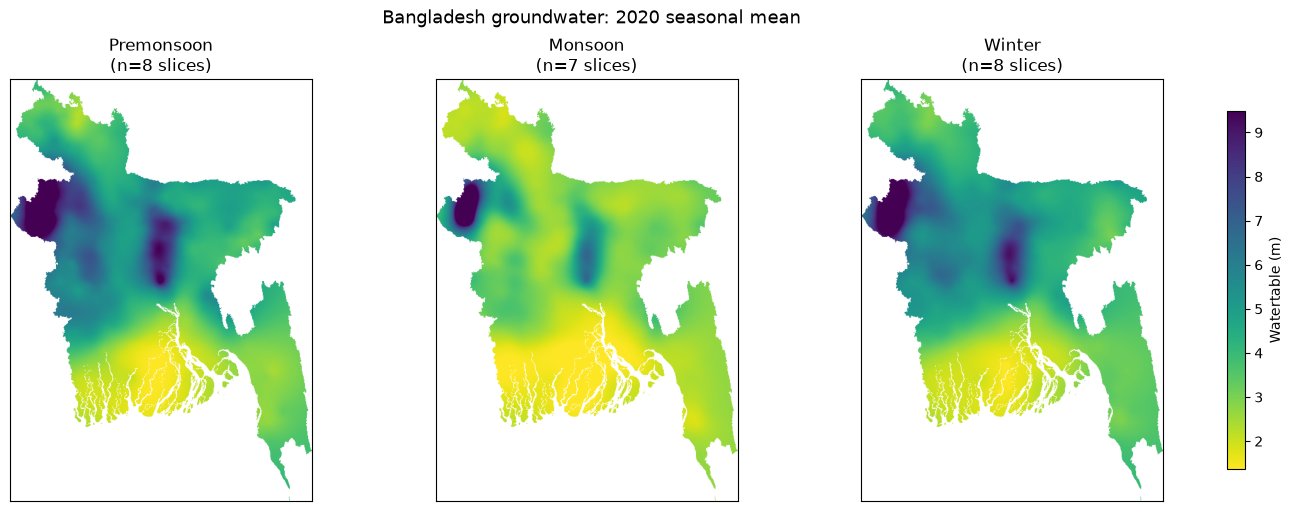

Domain-wide seasonal means (m):
  Premonsoon  :   4.516
  Monsoon     :   2.879
  Winter      :   4.393


In [5]:
# Map the three seasonal means
fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)  # create the figure and axes
vmin = float(np.nanpercentile(season_da.values, 2))  # compute vmin
vmax = float(np.nanpercentile(season_da.values, 98))  # compute vmax

for ax, season in zip(axes, season_order):  # iterate over items
    data = seasonal_means[season].values  # data
    im = ax.imshow(data, cmap="viridis_r", vmin=vmin, vmax=vmax, origin="upper")  # show a 2-D array as an image
    ax.set_title(f"{season}\n(n={len(season_indices[season])} slices)")  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, label="Watertable (m)")  # add a colorbar
fig.suptitle(f"Bangladesh groundwater: {YEAR_WT} seasonal mean", fontsize=13)
plt.show()  # render the figure

print("Domain-wide seasonal means (m):")  # status / summary print
for s in season_order:  # iterate over items
    if s in seasonal_means:
        print(f"  {s:12s}: {float(np.nanmean(seasonal_means[s].values)):7.3f}")  # status / summary print


### Optional: calendar seasons via `aggregate_multidimensional_raster`

The library also supports standard meteorological seasons (`DJF`, `MAM`, `JJA`, `SON`)
and `MONTHLY` / `YEARLY` keywords: useful when you want ArcGIS-style aggregation
without custom season boundaries.


MAM (Mar-May) aggregate: MultidimensionalRaster(variables=[watertable], dims={time: 1, y: 669, x: 479})


Monthly aggregate: MultidimensionalRaster(variables=[watertable], dims={y: 669, x: 479, time: 12})
Monthly time stamps: ['2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01', '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01', '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01']


Text(0.5, 0, 'Longitude')

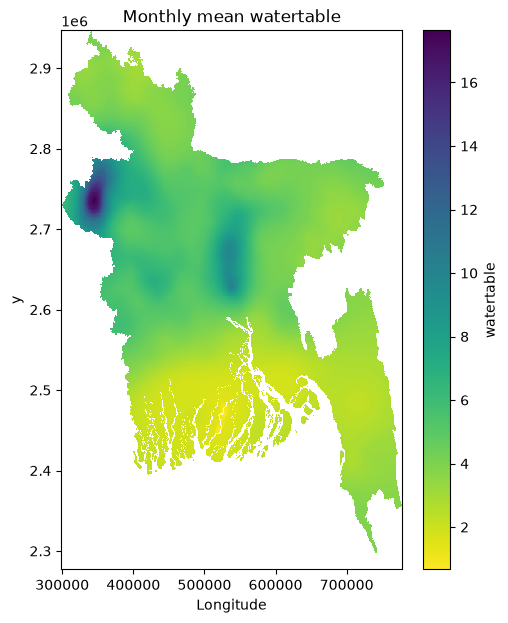

In [6]:
# Example: meteorological MAM mean for the same 2020 cube
mam = aggregate_multidimensional_raster(  # mam
    wt_mdr,
    variable="watertable",  # variable
    dimension="time",  # dimension
    aggregation_method="MEAN",  # aggregation_method
    aggregation_definition="INTERVAL_KEYWORD",  # aggregation_definition
    interval_keyword="MAM",  # interval_keyword
)
print("MAM (Mar-May) aggregate:", mam)  # status / summary print

# Example: monthly means for 2020 watertable
wt_monthly = aggregate_multidimensional_raster(  # wt_monthly
    wt_mdr,
    variable="watertable",  # variable
    dimension="time",  # dimension
    aggregation_method="MEAN",  # aggregation_method
    aggregation_definition="INTERVAL_KEYWORD",  # aggregation_definition
    interval_keyword="MONTHLY",  # interval_keyword
)
print("Monthly aggregate:", wt_monthly)  # status / summary print
print("Monthly time stamps:", [str(t)[:10] for t in wt_monthly.dataset.time.values])  # status / summary print

# Plot monthly means
fig, ax = plt.subplots(figsize=(5.5, 7))  # create the figure and axes
wt_monthly.dataset.watertable.isel(time=0).plot(ax=ax, cmap="viridis_r")  # draw the map or chart
ax.set_title("Monthly mean watertable")  # panel title
ax.set_xlabel("Longitude")  # x-axis label


## NDVI 2024: monthly mean (12 months)

Stack all **2024** 16-day NDVI GeoTIFFs, scale from MODIS integer units
(`DN x 1e-4`), then aggregate to **12 monthly means** with
`aggregate_multidimensional_raster`.


In [7]:
YEAR_NDVI = 2024  # tutorial parameter
NDVI_SCALE = 1e-4  # MODIS NDVI stored as int16 x 10000

ndvi_paths = sorted(  # ndvi_paths
    NDVI_DIR.glob(f"ndvi_{YEAR_NDVI}_*.tif"),
    key=lambda p: parse_doy_filename(p, "ndvi"),  # key
)
if not ndvi_paths:
    raise FileNotFoundError(f"No ndvi_{YEAR_NDVI}_*.tif under {NDVI_DIR}")  # fail with a clear error message

ndvi_times = [parse_doy_filename(p, "ndvi") for p in ndvi_paths]  # ndvi_times
ndvi_mdr = stack_geotiffs_to_mdr(  # ndvi_mdr
    ndvi_paths, ndvi_times, variable_name="ndvi", scale=NDVI_SCALE  # ndvi_paths
)

# Valid NDVI typically in [-0.2, 1]; mask remaining fill / out-of-range
ndvi_da = ndvi_mdr.dataset["ndvi"]  # ndvi_da
ndvi_da = ndvi_da.where((ndvi_da >= -0.2) & (ndvi_da <= 1.0))  # ndvi_da
ndvi_mdr = MultidimensionalRaster(ndvi_da.to_dataset(name="ndvi"))  # ndvi_mdr

print(f"Loaded {len(ndvi_paths)} NDVI 16-day slices for {YEAR_NDVI}")  # status / summary print
print(f"Time span: {ndvi_times[0].date()} -> {ndvi_times[-1].date()}")  # status / summary print
print(ndvi_mdr)  # status / summary print
print("Sample dates:", [t.strftime("%Y-%m-%d") for t in ndvi_times[:4]], "…")  # status / summary print


Loaded 23 NDVI 16-day slices for 2024
Time span: 2024-01-01 -> 2024-12-18
MultidimensionalRaster(variables=[ndvi], dims={time: 23, y: 670, x: 480})
Sample dates: ['2024-01-01', '2024-01-17', '2024-02-02', '2024-02-18'] …


In [8]:
# Aggregate 16-day NDVI -> monthly mean (12 months)
ndvi_monthly = aggregate_multidimensional_raster(  # ndvi_monthly
    ndvi_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    aggregation_method="MEAN",  # aggregation_method
    aggregation_definition="INTERVAL_KEYWORD",  # aggregation_definition
    interval_keyword="MONTHLY",  # interval_keyword
)
print(ndvi_monthly)  # status / summary print

month_da = ndvi_monthly.dataset["ndvi"]  # month_da
month_times = [np.datetime_as_string(t, unit="M") for t in month_da.time.values]  # month_times
print(f"Monthly layers: {len(month_da.time)} -> {month_times}")  # status / summary print

# Export each month as GeoTIFF + combined NetCDF
ref_ndvi = ndvi_paths[0]  # ref_ndvi
for i, t in enumerate(month_da.time.values):  # iterate over items
    label = np.datetime_as_string(t, unit="M").replace("-", "")  # YYYYMM
    out_tif = NDVI_MONTH_DIR / f"ndvi_{YEAR_NDVI}_mean_{label}.tif"  # out_tif
    write_geotiff_from_array(month_da.isel(time=i).values, out_tif, ref_ndvi)
    print(f"Wrote {out_tif.name}")  # status / summary print

NDVI_MONTH_NC = OUT_DIR / f"ndvi_{YEAR_NDVI}_monthly_mean.nc"  # NDVI_MONTH_NC
raster_to_netcdf(
    ndvi_monthly,
    NDVI_MONTH_NC,
    overwrite=True,  # overwrite
    encoding={"ndvi": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
print(f"Wrote {NDVI_MONTH_NC}")  # status / summary print


MultidimensionalRaster(variables=[ndvi], dims={y: 670, x: 480, time: 12})
Monthly layers: 12 -> [np.str_('2024-01'), np.str_('2024-02'), np.str_('2024-03'), np.str_('2024-04'), np.str_('2024-05'), np.str_('2024-06'), np.str_('2024-07'), np.str_('2024-08'), np.str_('2024-09'), np.str_('2024-10'), np.str_('2024-11'), np.str_('2024-12')]
Wrote ndvi_2024_mean_202401.tif
Wrote ndvi_2024_mean_202402.tif
Wrote ndvi_2024_mean_202403.tif
Wrote ndvi_2024_mean_202404.tif


Wrote ndvi_2024_mean_202405.tif
Wrote ndvi_2024_mean_202406.tif
Wrote ndvi_2024_mean_202407.tif
Wrote ndvi_2024_mean_202408.tif


Wrote ndvi_2024_mean_202409.tif
Wrote ndvi_2024_mean_202410.tif
Wrote ndvi_2024_mean_202411.tif
Wrote ndvi_2024_mean_202412.tif


Wrote /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/ndvi_2024_monthly_mean.nc


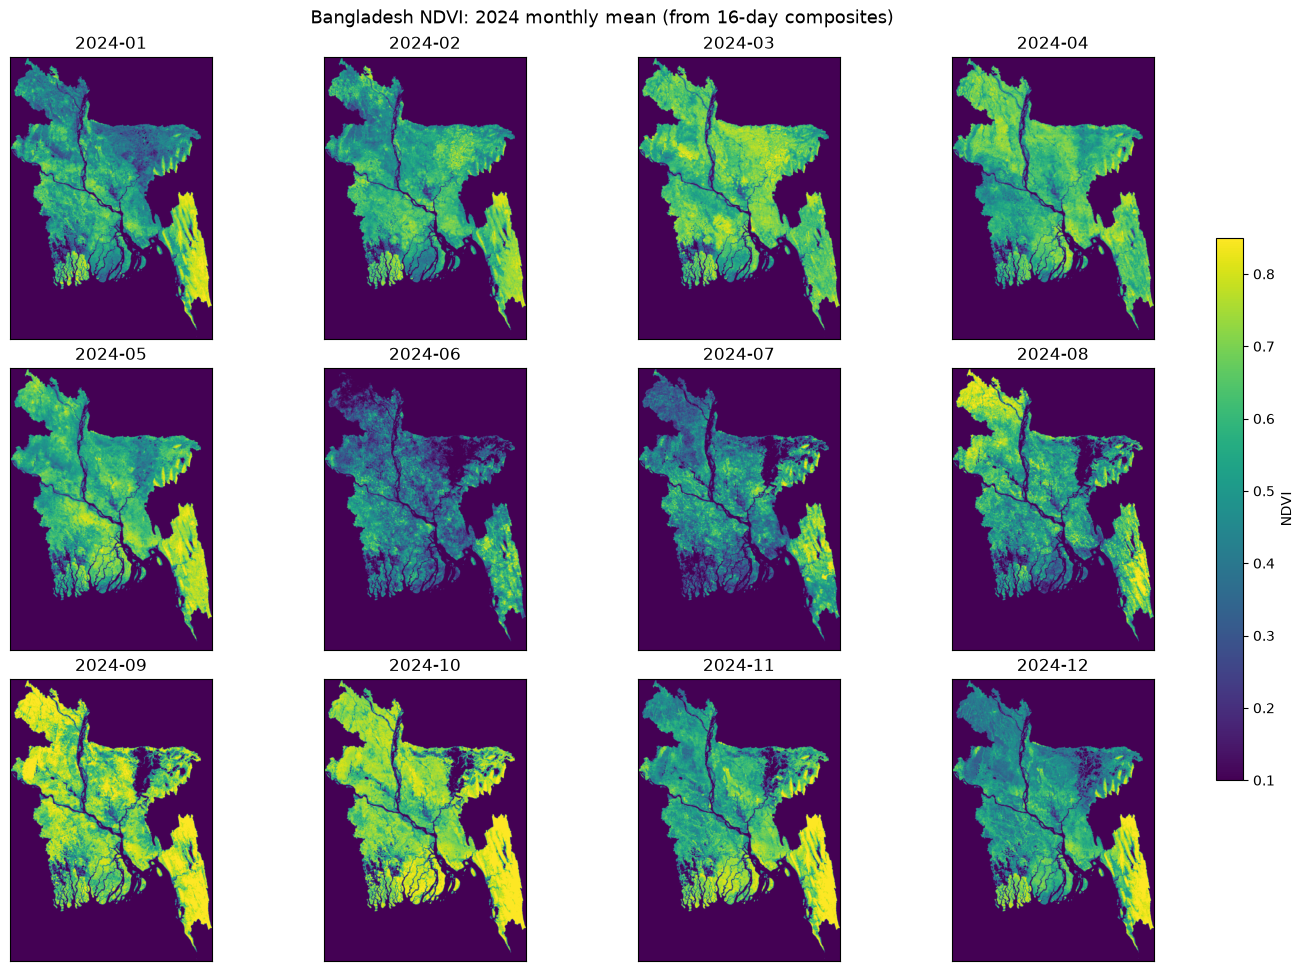

Domain-wide monthly mean NDVI:
  2024-01:  0.219
  2024-02:  0.237
  2024-03:  0.267
  2024-04:  0.254
  2024-05:  0.252
  2024-06:  0.156
  2024-07:  0.177
  2024-08:  0.218
  2024-09:  0.280
  2024-10:  0.285
  2024-11:  0.244
  2024-12:  0.218


In [9]:
# 12-panel monthly NDVI map, with background/NA as no color (completely transparent)

n_months = int(month_da.sizes["time"])  # n_months
ncols = 4  # ncols
nrows = int(np.ceil(n_months / ncols))  # compute nrows
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), constrained_layout=True)  # create the figure and axes
axes = np.atleast_1d(axes).ravel()  # compute axes

vmin, vmax = 0.1, 0.85  # vmin

# Get a colormap, make a copy, and set bad (NaN) values to fully transparent
cmap = plt.get_cmap("viridis").copy()  # cmap
cmap.set_bad((0, 0, 0, 0))

for i, ax in enumerate(axes):  # iterate over items
    if i < n_months:
        t = month_da.time.values[i]  # t
        label = np.datetime_as_string(t, unit="M")  # compute label
        arr = np.ma.masked_invalid(month_da.isel(time=i).values)  # select along coordinates or indices
        im = ax.imshow(  # im
            arr,
            cmap=cmap,  # cmap
            vmin=vmin,  # vmin
            vmax=vmax,  # vmax
            origin="upper"  # origin
        )
        ax.set_title(label)  # panel title
        ax.set_xticks([])  # configure tick labels
        ax.set_yticks([])  # configure tick labels
    else:
        ax.axis("off")

fig.colorbar(im, ax=axes.tolist(), shrink=0.6, label="NDVI")  # add a colorbar
fig.suptitle(
    f"Bangladesh NDVI: {YEAR_NDVI} monthly mean (from 16-day composites)",
    fontsize=13,  # fontsize
)
plt.show()  # render the figure

print("Domain-wide monthly mean NDVI:")  # status / summary print
for i, t in enumerate(month_da.time.values):  # iterate over items
    v = float(np.nanmean(month_da.isel(time=i).values))  # select along coordinates or indices
    print(f"  {np.datetime_as_string(t, unit='M')}: {v:6.3f}")  # status / summary print


## Multidimensional Anomaly

In this section, we will compute vegetation anomalies using NDVI data, 
specifically measuring how much the NDVI for each month in a target year 
(e.g., 2024) deviates from the "normal" value for that same month, based on a historical baseline.

This is accomplished by comparing recent NDVI observations to a **month-of-year climatology**: 
that is, long-term average NDVI values for each calendar month, calculated from several years of past data.

To do this, we use the function `generate_multidimensional_anomaly` (ArcGIS *Generate Multidimensional Anomaly* tool).
This tool allows us to:
- Stack multiple years of NDVI data to build up a climatology for each month (e.g., average all Januarys, all Februarys, etc., across many years)
- Calculate, for each month in a given year, how different the observed NDVI is from its long-term monthly average
- Express this anomaly as either the absolute difference, percent difference, or standardized z-score

This workflow enables us to spot unusually green or brown months and detect significant changes in vegetation conditions.

**Workflow**
1. Stack 16-day NDVI for a baseline window (**2015-2024**)
2. Aggregate to monthly means
3. Compute anomalies with `calculation_interval="BY_MONTH"`:
   - `DIFFERENCE_FROM_MEAN`: NDVI units above/below the month mean
   - `PERCENT_DIFFERENCE_FROM_MEAN`: relative (%) departure
   - `Z_SCORE`: standardized departure
4. Map and export **2024** monthly anomalies

Positive values = greener / denser vegetation than the month climatology; negative = browner.


In [10]:
# Build multi-year NDVI cube (16-day -> monthly) for climatology + anomaly
NDVI_SCALE = 1e-4  # tutorial parameter
ANOM_YEARS = range(2015, 2025)  # 2015-2024 baseline window
TARGET_ANOM_YEAR = 2024  # TARGET_ANOM_YEAR

ndvi_paths_clim = []  # ndvi_paths_clim
for year in ANOM_YEARS:  # iterate over items
    ndvi_paths_clim.extend(NDVI_DIR.glob(f"ndvi_{year}_*.tif"))
ndvi_paths_clim = sorted(ndvi_paths_clim, key=lambda p: parse_doy_filename(p, "ndvi"))  # ndvi_paths_clim
if not ndvi_paths_clim:
    raise FileNotFoundError(f"No NDVI GeoTIFFs for {min(ANOM_YEARS)}-{max(ANOM_YEARS)} under {NDVI_DIR}")  # fail with a clear error message

ndvi_times_clim = [parse_doy_filename(p, "ndvi") for p in ndvi_paths_clim]  # ndvi_times_clim
print(  # status / summary print
    f"Loading {len(ndvi_paths_clim)} NDVI 16-day slices "
    f"({ndvi_times_clim[0].date()} -> {ndvi_times_clim[-1].date()})…"
)

ndvi_clim_mdr = stack_geotiffs_to_mdr(  # ndvi_clim_mdr
    ndvi_paths_clim, ndvi_times_clim, variable_name="ndvi", scale=NDVI_SCALE  # ndvi_paths_clim
)
ndvi_clim_da = ndvi_clim_mdr.dataset["ndvi"]  # ndvi_clim_da
ndvi_clim_da = ndvi_clim_da.where((ndvi_clim_da >= -0.2) & (ndvi_clim_da <= 1.0))  # ndvi_clim_da
ndvi_clim_mdr = MultidimensionalRaster(ndvi_clim_da.to_dataset(name="ndvi"))  # ndvi_clim_mdr

# Aggregate 16-day -> monthly means (required for BY_MONTH climatology)
ndvi_monthly_clim = aggregate_multidimensional_raster(  # ndvi_monthly_clim
    ndvi_clim_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    aggregation_method="MEAN",  # aggregation_method
    aggregation_definition="INTERVAL_KEYWORD",  # aggregation_definition
    interval_keyword="MONTHLY",  # interval_keyword
)
print(ndvi_monthly_clim)  # status / summary print
print(  # status / summary print
    "Monthly time:",
    str(ndvi_monthly_clim.dataset.time.values[0])[:7],
    "->",
    str(ndvi_monthly_clim.dataset.time.values[-1])[:7],
    f"(n={ndvi_monthly_clim.dataset.sizes['time']})",  # set f"(n
)


Loading 230 NDVI 16-day slices (2015-01-01 -> 2024-12-18)…


MultidimensionalRaster(variables=[ndvi], dims={y: 670, x: 480, time: 120})
Monthly time: 2015-01 -> 2024-12 (n=120)


In [11]:
# Generate multidimensional anomalies (month-of-year baseline)
anom_diff = generate_multidimensional_anomaly(  # anom_diff
    ndvi_monthly_clim,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    anomaly_type="DIFFERENCE_FROM_MEAN",  # anomaly_type
    calculation_interval="BY_MONTH",  # calculation_interval
)
anom_pct = generate_multidimensional_anomaly(  # anom_pct
    ndvi_monthly_clim,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    anomaly_type="PERCENT_DIFFERENCE_FROM_MEAN",  # anomaly_type
    calculation_interval="BY_MONTH",  # calculation_interval
)
anom_z = generate_multidimensional_anomaly(  # anom_z
    ndvi_monthly_clim,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    anomaly_type="Z_SCORE",  # anomaly_type
    calculation_interval="BY_MONTH",  # calculation_interval
)

print("Difference-from-mean:", anom_diff)  # status / summary print
print("Percent difference:  ", anom_pct)  # status / summary print
print("Z-score:             ", anom_z)  # status / summary print

# Domain-wide mean anomaly should be near zero over the full climatology window
print(  # status / summary print
    "Mean anomaly (all months, NDVI units):",
    f"{float(np.nanmean(anom_diff.dataset['ndvi'].values)):.4f}",
)


Difference-from-mean: MultidimensionalRaster(variables=[ndvi], dims={y: 670, x: 480, time: 120})
Percent difference:   MultidimensionalRaster(variables=[ndvi], dims={y: 670, x: 480, time: 120})
Z-score:              MultidimensionalRaster(variables=[ndvi], dims={y: 670, x: 480, time: 120})
Mean anomaly (all months, NDVI units): 0.0000


In [12]:
# Extract / export 2024 monthly anomalies
def select_year(mdr: MultidimensionalRaster, year: int) -> xr.DataArray:
    da = mdr.dataset["ndvi"]  # da
    return da.sel(time=da.time.dt.year == year)  # return the computed result


anom2024_diff = select_year(anom_diff, TARGET_ANOM_YEAR)  # anom2024_diff
anom2024_pct = select_year(anom_pct, TARGET_ANOM_YEAR)  # anom2024_pct
anom2024_z = select_year(anom_z, TARGET_ANOM_YEAR)  # anom2024_z

print(f"{TARGET_ANOM_YEAR} difference anomaly months:", int(anom2024_diff.sizes["time"]))  # status / summary print
print([np.datetime_as_string(t, unit="M") for t in anom2024_diff.time.values])  # status / summary print

# Write NetCDF cubes (full window + 2024 subset)
NDVI_ANOM_NC = NDVI_ANOM_DIR / "ndvi_2015_2024_anomaly_diff_by_month.nc"  # build a filesystem path
NDVI_ANOM_Z_NC = NDVI_ANOM_DIR / "ndvi_2015_2024_anomaly_zscore_by_month.nc"  # build a filesystem path
NDVI_ANOM_2024_NC = NDVI_ANOM_DIR / f"ndvi_{TARGET_ANOM_YEAR}_anomaly_diff_by_month.nc"  # NDVI_ANOM_2024_NC

raster_to_netcdf(
    anom_diff,
    NDVI_ANOM_NC,
    overwrite=True,  # overwrite
    encoding={"ndvi": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
raster_to_netcdf(
    anom_z,
    NDVI_ANOM_Z_NC,
    overwrite=True,  # overwrite
    encoding={"ndvi": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
raster_to_netcdf(
    MultidimensionalRaster(anom2024_diff.to_dataset(name="ndvi")),
    NDVI_ANOM_2024_NC,
    overwrite=True,  # overwrite
    encoding={"ndvi": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)

# GeoTIFFs for 2024 difference anomalies
ref_ndvi_anom = next(NDVI_DIR.glob(f"ndvi_{TARGET_ANOM_YEAR}_*.tif"))  # collect matching files
for i, t in enumerate(anom2024_diff.time.values):  # iterate over items
    label = np.datetime_as_string(t, unit="M").replace("-", "")  # compute label
    out_tif = NDVI_ANOM_DIR / f"ndvi_{TARGET_ANOM_YEAR}_anom_diff_{label}.tif"  # out_tif
    write_geotiff_from_array(anom2024_diff.isel(time=i).values, out_tif, ref_ndvi_anom)
    print(f"Wrote {out_tif.name}")  # status / summary print

print(f"Wrote {NDVI_ANOM_NC.name}")  # status / summary print
print(f"Wrote {NDVI_ANOM_Z_NC.name}")  # status / summary print
print(f"Wrote {NDVI_ANOM_2024_NC.name}")  # status / summary print


2024 difference anomaly months: 12
[np.str_('2024-01'), np.str_('2024-02'), np.str_('2024-03'), np.str_('2024-04'), np.str_('2024-05'), np.str_('2024-06'), np.str_('2024-07'), np.str_('2024-08'), np.str_('2024-09'), np.str_('2024-10'), np.str_('2024-11'), np.str_('2024-12')]


Wrote ndvi_2024_anom_diff_202401.tif
Wrote ndvi_2024_anom_diff_202402.tif
Wrote ndvi_2024_anom_diff_202403.tif
Wrote ndvi_2024_anom_diff_202404.tif
Wrote ndvi_2024_anom_diff_202405.tif
Wrote ndvi_2024_anom_diff_202406.tif
Wrote ndvi_2024_anom_diff_202407.tif
Wrote ndvi_2024_anom_diff_202408.tif
Wrote ndvi_2024_anom_diff_202409.tif
Wrote ndvi_2024_anom_diff_202410.tif


Wrote ndvi_2024_anom_diff_202411.tif
Wrote ndvi_2024_anom_diff_202412.tif
Wrote ndvi_2015_2024_anomaly_diff_by_month.nc
Wrote ndvi_2015_2024_anomaly_zscore_by_month.nc
Wrote ndvi_2024_anomaly_diff_by_month.nc


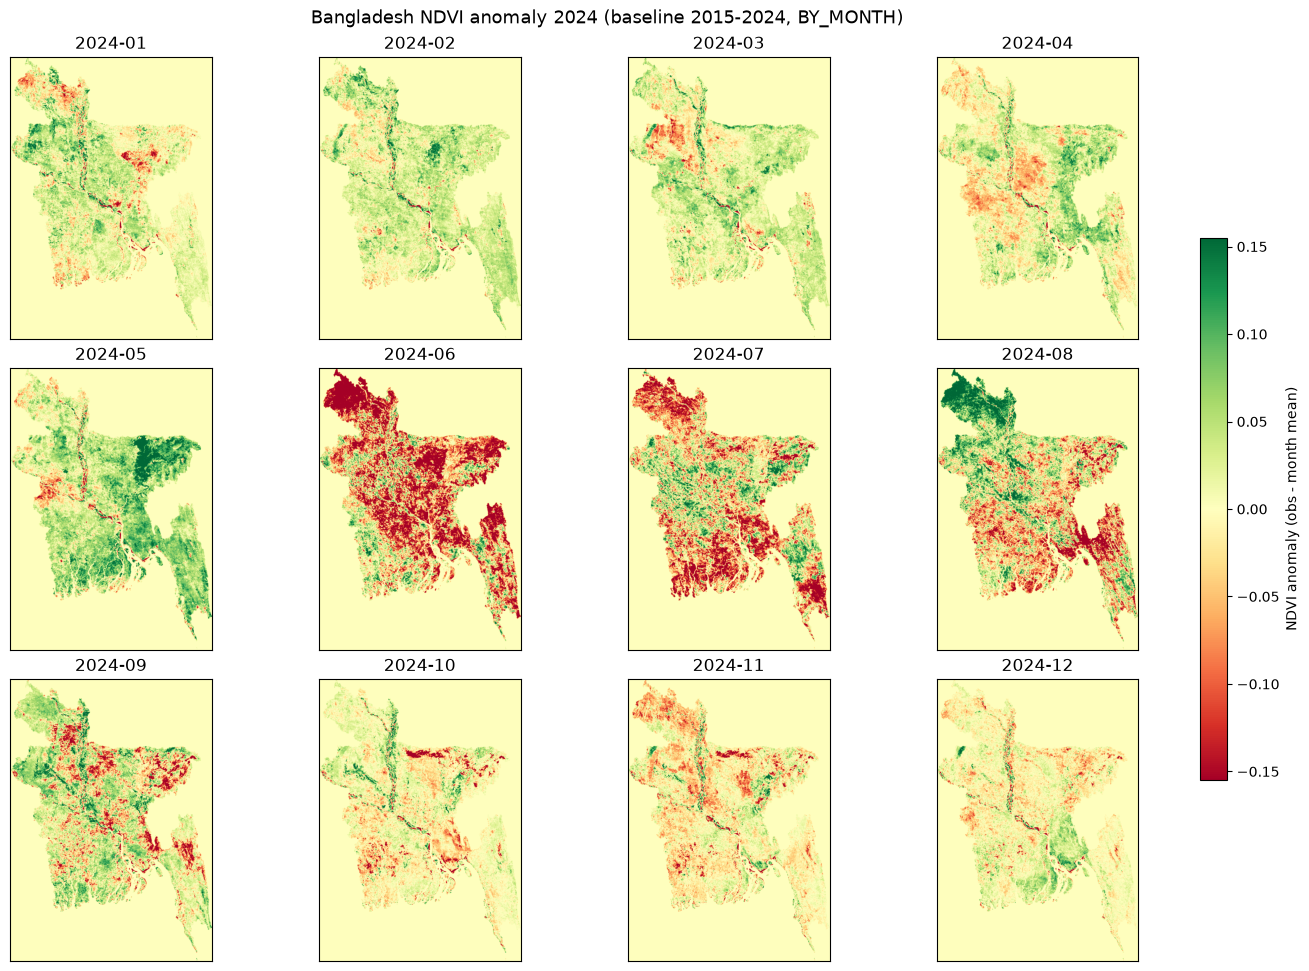

Domain-wide 2024 monthly mean anomalies:
   Month     ΔNDVI     %diff         z
 2024-01     0.007      -inf      0.45
 2024-02     0.012      -inf      0.73
 2024-03     0.008      -inf      0.43
 2024-04     0.004       inf      0.14
 2024-05     0.022  232644.5      0.72
 2024-06    -0.032       nan     -0.69
 2024-07    -0.014       nan     -0.33
 2024-08    -0.001       nan     -0.06
 2024-09     0.003      -inf      0.14
 2024-10    -0.002      -inf     -0.12
 2024-11    -0.007       inf     -0.37
 2024-12    -0.000       nan     -0.02


In [13]:
# Map 2024 monthly NDVI anomalies (difference from month-of-year mean)
n_months = int(anom2024_diff.sizes["time"])  # n_months
ncols, nrows = 4, int(np.ceil(n_months / 4))  # compute ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), constrained_layout=True)  # create the figure and axes
axes = np.atleast_1d(axes).ravel()  # compute axes

# Symmetric color scale around 0
lim = float(np.nanpercentile(np.abs(anom2024_diff.values), 98))  # compute lim
lim = max(lim, 0.05)  # lim

for i in range(n_months):  # iterate over items
    ax = axes[i]  # ax
    label = np.datetime_as_string(anom2024_diff.time.values[i], unit="M")  # compute label
    data = anom2024_diff.isel(time=i).values  # select along coordinates or indices
    im = ax.imshow(data, cmap="RdYlGn", vmin=-lim, vmax=lim, origin="upper")  # show a 2-D array as an image
    ax.set_title(label)  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

for j in range(n_months, len(axes)):  # iterate over items
    axes[j].axis("off")

fig.colorbar(im, ax=axes.tolist(), shrink=0.6, label="NDVI anomaly (obs - month mean)")  # add a colorbar
fig.suptitle(
    f"Bangladesh NDVI anomaly {TARGET_ANOM_YEAR} "
    f"(baseline {min(ANOM_YEARS)}-{max(ANOM_YEARS)}, BY_MONTH)",
    fontsize=13,  # fontsize
)
plt.show()  # render the figure

print(f"Domain-wide {TARGET_ANOM_YEAR} monthly mean anomalies:")  # status / summary print
print(f"{'Month':>8}  {'ΔNDVI':>8}  {'%diff':>8}  {'z':>8}")  # status / summary print
for i, t in enumerate(anom2024_diff.time.values):  # iterate over items
    d = float(np.nanmean(anom2024_diff.isel(time=i).values))  # select along coordinates or indices
    p = float(np.nanmean(anom2024_pct.isel(time=i).values))  # select along coordinates or indices
    z = float(np.nanmean(anom2024_z.isel(time=i).values))  # select along coordinates or indices
    print(f"{np.datetime_as_string(t, unit='M'):>8}  {d:8.3f}  {p:8.1f}  {z:8.2f}")  # status / summary print


Greener-than-usual months (highest mean z):
  2024-02: z = +0.73
  2024-05: z = +0.72
  2024-01: z = +0.45
Browner-than-usual months (lowest mean z):
  2024-07: z = -0.33
  2024-11: z = -0.37
  2024-06: z = -0.69


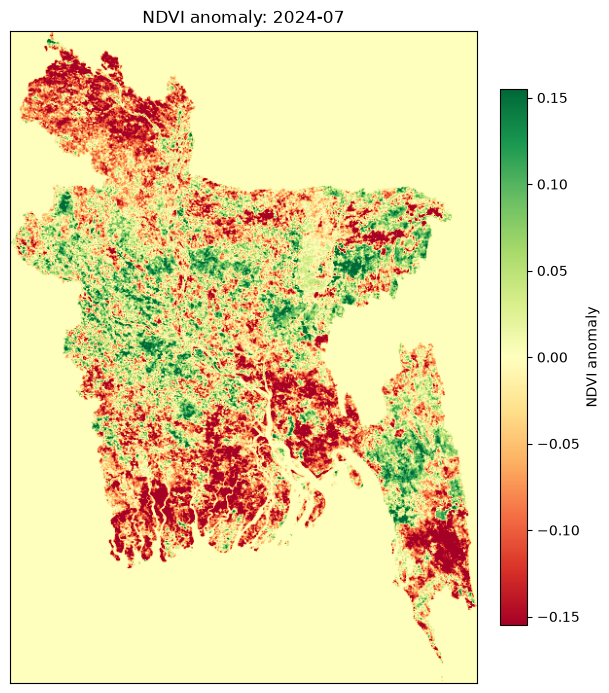

In [14]:
# Peak green-up / browning months in 2024 (spatial mean of z-score)
z_means = [  # z_means
    (np.datetime_as_string(t, unit="M"), float(np.nanmean(anom2024_z.isel(time=i).values)))  # select a subset of the cube
    for i, t in enumerate(anom2024_z.time.values)
]
z_means_sorted = sorted(z_means, key=lambda x: x[1], reverse=True)  # z_means_sorted
print("Greener-than-usual months (highest mean z):")  # status / summary print
for m, z in z_means_sorted[:3]:  # iterate over items
    print(f"  {m}: z = {z:+.2f}")  # status / summary print
print("Browner-than-usual months (lowest mean z):")  # status / summary print
for m, z in z_means_sorted[-3:]:  # iterate over items
    print(f"  {m}: z = {z:+.2f}")  # status / summary print

# Single-panel example: July anomaly (monsoon peak greenness)
july = anom2024_diff.sel(time=anom2024_diff.time.dt.month == 7).isel(time=0)  # select along coordinates or indices
fig, ax = plt.subplots(figsize=(6, 7), constrained_layout=True)  # create the figure and axes
im = ax.imshow(july.values, cmap="RdYlGn", vmin=-lim, vmax=lim, origin="upper")  # show a 2-D array as an image
ax.set_title(f"NDVI anomaly: {np.datetime_as_string(july.time.values, unit='M')}")  # panel title
ax.set_xticks([])  # configure tick labels
ax.set_yticks([])  # configure tick labels
fig.colorbar(im, ax=ax, shrink=0.8, label="NDVI anomaly")  # add a colorbar
plt.show()  # render the figure


## Find Argument Statistics (NDVI)

In spatiotemporal raster analysis, it is often useful to determine **when** a particular
statistic (e.g., a maximum or minimum value) occurs for each pixel over time.
This is achieved by identifying, for each spatial location, the time index (or timestamp)
at which a specified statistic (such as the maximum NDVI) is reached, rather than just
reporting the value itself.

In this section, we use the function `find_argument_statistics`, which performs the so-called
*argument* statistics commonly referred to in ArcGIS as *Find Argument Statistics*, to
extract, for each pixel, the **time-dimension value** (e.g., date or index) at which
the desired condition is satisfied (e.g., maximum or minimum NDVI).

For example, by applying `find_argument_statistics` to a time series of NDVI images, we can
create a new raster layer where each pixel encodes the time (such as day-of-year or date)
of peak greenness (NDVI maximum), lowest greenness (NDVI minimum), or first threshold crossing.

This approach enables spatial mapping of ecological timing metrics, such as:
- Date of maximum NDVI (peak greenness)
- Date of minimum NDVI (senescence or disturbance)
- Duration and timing of greenness thresholds (e.g., number of time slices above NDVI = 0.5)
- First date when a pixel reaches a certain NDVI threshold

These argument statistics provide valuable insight into seasonal vegetation dynamics and
can reveal spatial patterns in phenology or environmental events.

We use the **2024** 16-day NDVI stack from `Data/00_shared/raster_data/Bangladesh/ndvi`:

| `statistics_type` | Result per pixel |
|---|---|
| `ARGUMENT_OF_MAXIMUM` | Date of maximum NDVI (peak greenness) |
| `ARGUMENT_OF_MINIMUM` | Date of minimum NDVI |
| `DURATION` + `min_value` | Number of 16-day composites with NDVI ≥ threshold |
| `ARGUMENT_OF_MIN_VALUE` | First date when NDVI reaches the threshold |

Datetime argument layers are also exported as **day-of-year (DOY)** GeoTIFFs for mapping.


In [15]:
# NDVI 2024 cube for argument statistics (16-day composites)
ARG_YEAR = 2024  # tutorial parameter
NDVI_SCALE = 1e-4  # tutorial parameter
NDVI_THRESHOLD = 0.50  # "green" vegetation threshold for DURATION / first-crossing

arg_paths = sorted(  # arg_paths
    NDVI_DIR.glob(f"ndvi_{ARG_YEAR}_*.tif"),
    key=lambda p: parse_doy_filename(p, "ndvi"),  # key
)
if not arg_paths:
    raise FileNotFoundError(f"No ndvi_{ARG_YEAR}_*.tif under {NDVI_DIR}")  # fail with a clear error message

arg_times = [parse_doy_filename(p, "ndvi") for p in arg_paths]  # arg_times
ndvi_arg_mdr = stack_geotiffs_to_mdr(  # ndvi_arg_mdr
    arg_paths, arg_times, variable_name="ndvi", scale=NDVI_SCALE  # arg_paths
)
ndvi_arg_da = ndvi_arg_mdr.dataset["ndvi"]  # ndvi_arg_da
ndvi_arg_da = ndvi_arg_da.where((ndvi_arg_da >= -0.2) & (ndvi_arg_da <= 1.0))  # ndvi_arg_da
# Mask persistent near-zero background (water / fill) so argument stats reflect vegetated land
land_mask = ndvi_arg_da.max(dim="time", skipna=True) >= 0.15  # land_mask
ndvi_arg_da = ndvi_arg_da.where(land_mask)  # ndvi_arg_da
ndvi_arg_mdr = MultidimensionalRaster(ndvi_arg_da.to_dataset(name="ndvi"))  # ndvi_arg_mdr
print(f"Vegetated land pixels: {int(land_mask.sum())} / {land_mask.size}")  # status / summary print

print(f"Loaded {len(arg_paths)} NDVI slices for {ARG_YEAR}")  # status / summary print
print(f"Time span: {arg_times[0].date()} -> {arg_times[-1].date()}")  # status / summary print
print(ndvi_arg_mdr)  # status / summary print


Vegetated land pixels: 140860 / 321600
Loaded 23 NDVI slices for 2024
Time span: 2024-01-01 -> 2024-12-18
MultidimensionalRaster(variables=[ndvi], dims={time: 23, y: 670, x: 480})


In [16]:
# 1) Date of maximum / minimum NDVI
arg_max = find_argument_statistics(  # arg_max
    ndvi_arg_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    statistics_type="ARGUMENT_OF_MAXIMUM",  # statistics_type
    multiple_occurrence="FIRST_OCCURRENCE",  # multiple_occurrence
)
arg_min = find_argument_statistics(  # arg_min
    ndvi_arg_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    statistics_type="ARGUMENT_OF_MINIMUM",  # statistics_type
    multiple_occurrence="FIRST_OCCURRENCE",  # multiple_occurrence
)

# 2) Duration above greenness threshold (count of 16-day slices)
arg_duration = find_argument_statistics(  # arg_duration
    ndvi_arg_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    statistics_type="DURATION",  # statistics_type
    min_value=NDVI_THRESHOLD,  # min_value
)

# 3) First date when NDVI reaches the threshold
arg_first_green = find_argument_statistics(  # arg_first_green
    ndvi_arg_mdr,
    variable="ndvi",  # variable
    dimension="time",  # dimension
    statistics_type="ARGUMENT_OF_MIN_VALUE",  # statistics_type
    min_value=NDVI_THRESHOLD,  # min_value
    multiple_occurrence="FIRST_OCCURRENCE",  # multiple_occurrence
)

print("ARGUMENT_OF_MAXIMUM:", arg_max)  # status / summary print
print("ARGUMENT_OF_MINIMUM:", arg_min)  # status / summary print
print("DURATION:           ", arg_duration)  # status / summary print
print("ARGUMENT_OF_MIN_VALUE (first ≥ threshold):", arg_first_green)  # status / summary print
print("Variables:", arg_max.variables, "|", arg_duration.variables)  # status / summary print


ARGUMENT_OF_MAXIMUM: MultidimensionalRaster(variables=[ndvi_arg_max, ndvi_arg_max_ordinal], dims={y: 670, x: 480})
ARGUMENT_OF_MINIMUM: MultidimensionalRaster(variables=[ndvi_arg_min, ndvi_arg_min_ordinal], dims={y: 670, x: 480})
DURATION:            MultidimensionalRaster(variables=[ndvi_duration], dims={y: 670, x: 480})
ARGUMENT_OF_MIN_VALUE (first ≥ threshold): MultidimensionalRaster(variables=[ndvi_arg_threshold, ndvi_arg_threshold_ordinal], dims={y: 670, x: 480})
Variables: ['ndvi_arg_max', 'ndvi_arg_max_ordinal'] | ['ndvi_duration']


In [17]:
# Convert datetime argument layers -> day-of-year for mapping / GeoTIFF export
def datetime_layer_to_doy(da: xr.DataArray) -> np.ndarray:
    """Datetime / ns-int argument array -> day-of-year float grid (NaN where missing)."""
    flat = np.asarray(da.values).ravel()  # compute flat
    out = np.full(flat.shape, np.nan, dtype=np.float32)  # compute out
    for i, val in enumerate(flat):  # iterate over items
        try:  # attempt optional or version-sensitive call
            ts = pd.Timestamp(val)  # compute ts
            if pd.isna(ts):
                continue  # skip this candidate
            out[i] = float(ts.dayofyear)  # set out[i]
        except Exception:  # handle the failure path
            continue  # skip this candidate
    return out.reshape(da.shape)  # return the computed result


doy_max = datetime_layer_to_doy(arg_max.dataset["ndvi_arg_max"])  # doy_max
doy_min = datetime_layer_to_doy(arg_min.dataset["ndvi_arg_min"])  # doy_min
doy_first = datetime_layer_to_doy(arg_first_green.dataset["ndvi_arg_threshold"])  # doy_first
duration = arg_duration.dataset["ndvi_duration"].values.astype(np.float32)  # cast to the target dtype

# Approximate days above threshold (each composite ~ 16 days)
duration_days = duration * 16.0  # duration_days

print(  # status / summary print
    "DOY of max NDVI: median:",
    f"{np.nanmedian(doy_max):.0f}",
    "| mean:",
    f"{np.nanmean(doy_max):.1f}",
)
print(  # status / summary print
    "DOY of min NDVI: median:",
    f"{np.nanmedian(doy_min):.0f}",
    "| mean:",
    f"{np.nanmean(doy_min):.1f}",
)
print(  # status / summary print
    f"Duration NDVI≥{NDVI_THRESHOLD}: median composites:",
    f"{np.nanmedian(duration):.0f}",
    f"(~ {np.nanmedian(duration_days):.0f} days)",
)
print(  # status / summary print
    "First DOY NDVI≥threshold: median:",
    f"{np.nanmedian(doy_first):.0f}",
)


DOY of max NDVI: median: 1 | mean: 99.4
DOY of min NDVI: median: 1 | mean: 82.9
Duration NDVI≥0.5: median composites: 0 (~ 0 days)
First DOY NDVI≥threshold: median: 1


In [18]:
# Export NetCDF + DOY / duration GeoTIFFs
ref_arg = arg_paths[0]  # ref_arg

# NetCDF: keep original argument outputs
for mdr_out, name in [
    (arg_max, f"ndvi_{ARG_YEAR}_arg_max.nc"),
    (arg_min, f"ndvi_{ARG_YEAR}_arg_min.nc"),
    (arg_duration, f"ndvi_{ARG_YEAR}_duration_ge_{str(NDVI_THRESHOLD).replace('.', 'p')}.nc"),
    (arg_first_green, f"ndvi_{ARG_YEAR}_first_ge_{str(NDVI_THRESHOLD).replace('.', 'p')}.nc"),
]:
    out_nc = NDVI_ARGSTAT_DIR / name  # out_nc
    raster_to_netcdf(mdr_out, out_nc, overwrite=True)  # set raster_to_netcdf(mdr_out
    print(f"Wrote {out_nc.name}")  # status / summary print

# GeoTIFF (numeric DOY / duration)
exports = {  # exports
    f"ndvi_{ARG_YEAR}_doy_of_max.tif": doy_max,
    f"ndvi_{ARG_YEAR}_doy_of_min.tif": doy_min,
    f"ndvi_{ARG_YEAR}_doy_first_ge_{str(NDVI_THRESHOLD).replace('.', 'p')}.tif": doy_first,
    f"ndvi_{ARG_YEAR}_duration_composites_ge_{str(NDVI_THRESHOLD).replace('.', 'p')}.tif": duration,
    f"ndvi_{ARG_YEAR}_duration_days_ge_{str(NDVI_THRESHOLD).replace('.', 'p')}.tif": duration_days,
}
for fname, arr in exports.items():  # iterate over items
    write_geotiff_from_array(arr, NDVI_ARGSTAT_DIR / fname, ref_arg)
    print(f"Wrote {fname}")  # status / summary print


Wrote ndvi_2024_arg_max.nc
Wrote ndvi_2024_arg_min.nc
Wrote ndvi_2024_duration_ge_0p5.nc
Wrote ndvi_2024_first_ge_0p5.nc
Wrote ndvi_2024_doy_of_max.tif


Wrote ndvi_2024_doy_of_min.tif
Wrote ndvi_2024_doy_first_ge_0p5.tif
Wrote ndvi_2024_duration_composites_ge_0p5.tif


Wrote ndvi_2024_duration_days_ge_0p5.tif


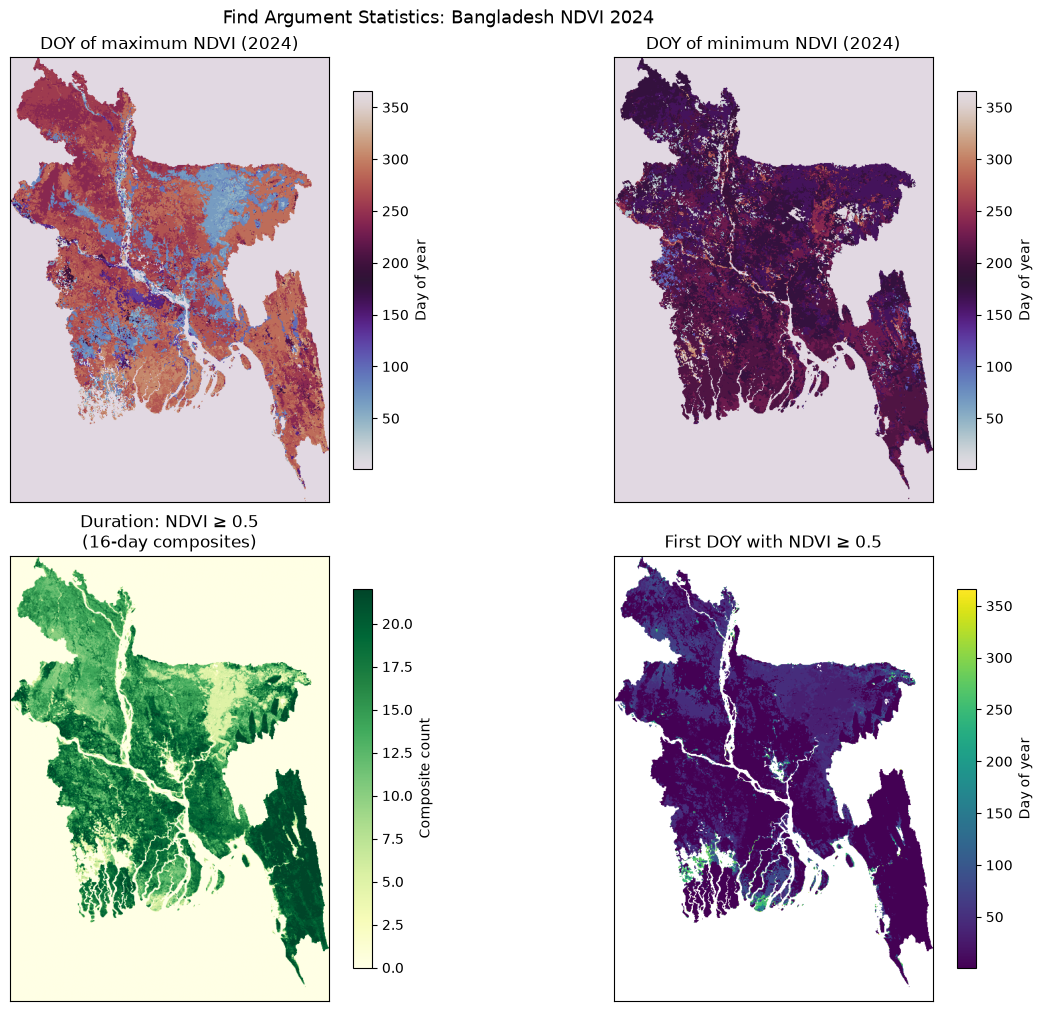

In [19]:
# Map argument statistics
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)  # create the figure and axes

# Date of max NDVI (DOY)
im0 = axes[0, 0].imshow(doy_max, cmap="twilight", vmin=1, vmax=366, origin="upper")  # show a 2-D array as an image
axes[0, 0].set_title(f"DOY of maximum NDVI ({ARG_YEAR})")  # panel title
fig.colorbar(im0, ax=axes[0, 0], shrink=0.85, label="Day of year")  # add a colorbar

# Date of min NDVI (DOY)
im1 = axes[0, 1].imshow(doy_min, cmap="twilight", vmin=1, vmax=366, origin="upper")  # show a 2-D array as an image
axes[0, 1].set_title(f"DOY of minimum NDVI ({ARG_YEAR})")  # panel title
fig.colorbar(im1, ax=axes[0, 1], shrink=0.85, label="Day of year")  # add a colorbar

# Duration above threshold
im2 = axes[1, 0].imshow(duration, cmap="YlGn", vmin=0, vmax=np.nanpercentile(duration, 98), origin="upper")  # show a 2-D array as an image
axes[1, 0].set_title(f"Duration: NDVI ≥ {NDVI_THRESHOLD}\n(16-day composites)")  # panel title
fig.colorbar(im2, ax=axes[1, 0], shrink=0.85, label="Composite count")  # add a colorbar

# First date reaching threshold
im3 = axes[1, 1].imshow(doy_first, cmap="viridis", vmin=1, vmax=366, origin="upper")  # show a 2-D array as an image
axes[1, 1].set_title(f"First DOY with NDVI ≥ {NDVI_THRESHOLD}")  # panel title
fig.colorbar(im3, ax=axes[1, 1], shrink=0.85, label="Day of year")  # add a colorbar

for ax in axes.ravel():  # iterate over items
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

fig.suptitle(
    f"Find Argument Statistics: Bangladesh NDVI {ARG_YEAR}",
    fontsize=13,  # fontsize
)
plt.show()  # render the figure


## Summary

| Product | Path |
|---|---|
| Watertable 2020 seasonal means (GeoTIFF) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/watertable_2020_seasonal_mean/` |
| Watertable 2020 seasonal mean (NetCDF) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/watertable_2020_seasonal_mean.nc` |
| NDVI 2024 monthly means (GeoTIFF) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/ndvi_2024_monthly_mean/` |
| NDVI 2024 monthly mean (NetCDF) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/ndvi_2024_monthly_mean.nc` |
| NDVI anomaly (2015-2024, BY_MONTH) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/ndvi_anomaly/` |
| NDVI argument statistics (2024) | `Data/03_spatial_analysis/NetCDF/output/multidimensional_analysis/ndvi_argument_statistics/` |

**Takeaways**
- Seasonal aggregation for groundwater uses hydrologic seasons (Premonsoon / Monsoon / Winter).
- Monthly aggregation for NDVI uses `aggregate_multidimensional_raster` with `interval_keyword="MONTHLY"`.
- Multidimensional anomalies use `generate_multidimensional_anomaly` with `calculation_interval="BY_MONTH"`.
- `find_argument_statistics` returns the **date** of max/min NDVI, **duration** above a threshold, or the first date a threshold is reached.
- Workflows start from 16-day GeoTIFF stacks wrapped as `MultidimensionalRaster` cubes.
